# Tech Challenge - Case Olist

**Objetivo:** analisar os dados de e-commerce da Olist entre 2016 e 2018 para identificar
oportunidades de melhoria e propor intervenções para os investidores e acionitas.

**Contexto:** a Olist é uma empresa brasileira que conecta pequenos vendedores a grandes
marketplaces. O vendedor anuncia pela Olist e envia o produto diretamente ao cliente.

**Glossário das principais colunas**

| Coluna | Significado |
|---|---|
| order_id | código do pedido |
| customer_id | código do cliente naquele pedido (muda a cada compra) |
| customer_unique_id | código da pessoa (cliente real) |
| customer_state | estado (UF) do cliente |
| order_status | situação do pedido |
| order_purchase_timestamp | data da compra |
| order_delivered_carrier_date | data em que o pedido foi entregue à transportadora |
| order_delivered_customer_date | data de entrega ao cliente |
| order_estimated_delivery_date | data prevista de entrega |
| order_item_id | número do item dentro do pedido |
| price | preço do produto |
| freight_value | valor do frete |
| payment_sequential | número do pagamento dentro do pedido |
| payment_type | forma de pagamento |
| review_score | nota da avaliação (1 a 5) |

## 01. Preparação (bibliotecas e caminho dos dados)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
caminho = '../files/'

## 02. Carregamento dos dados

In [3]:
clientes = pd.read_csv(caminho + 'olist_customers_dataset.csv')
geolocalizacao = pd.read_csv(caminho + 'olist_geolocation_dataset.csv')
itens = pd.read_csv(caminho + 'olist_order_items_dataset.csv')
pagamentos = pd.read_csv(caminho + 'olist_order_payments_dataset.csv')
avaliacoes = pd.read_csv(caminho + 'olist_order_reviews_dataset.csv')
pedidos = pd.read_csv(caminho + 'olist_orders_dataset.csv')
produtos = pd.read_csv(caminho + 'olist_products_dataset.csv')
vendedores = pd.read_csv(caminho + 'olist_sellers_dataset.csv')
categorias = pd.read_csv(caminho + 'product_category_name_translation.csv')


In [4]:
print('clientes:', clientes.shape)
print('geolocalizacao:', geolocalizacao.shape)
print('itens:', itens.shape)
print('pagamentos:', pagamentos.shape)
print('avaliacoes:', avaliacoes.shape)
print('pedidos:', pedidos.shape)
print('produtos:', produtos.shape)
print('vendedores:', vendedores.shape)
print('categorias:', categorias.shape)

clientes: (99441, 5)
geolocalizacao: (1000163, 5)
itens: (112650, 7)
pagamentos: (103886, 5)
avaliacoes: (99224, 7)
pedidos: (99441, 8)
produtos: (32951, 9)
vendedores: (3095, 4)
categorias: (71, 2)


As 9 tabelas foram carregadas e os tamanhos conferem com a base original.

## 03. Entendimento dos dados

### 3.1 Tabela pedidos

In [5]:
pedidos.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [6]:
pedidos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


**Observações:**

- 99.441 pedidos
- As colunas de data estão como texto (object)
- As datas de aprovação, envio e entrega têm quantidades menores que o total de pedidos, ligados a pedidos que não chegaram ao fim da jornada.

### 3.2 Status dos pedidos

In [7]:
contagem_status = pedidos['order_status'].value_counts()
print(contagem_status)
print('Total:', contagem_status.sum())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64
Total: 99441


**Observações:**

- 96.478 dos pedidos foram entregues (97%)
- A soma dos status bate com o total de pedidos (99.441)

### 3.3 Duplicados

In [8]:
print('pedidos duplicados: ', pedidos.duplicated().sum())
print('geolocalizacao duplicados:', geolocalizacao.duplicated().sum())

pedidos duplicados:  0
geolocalizacao duplicados: 261831


**Observações:**

- pedidos: 0 duplicados
- geolocalização: 261.831 duplicados

### 3.4 Granularidade

In [9]:
itens.head(10)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14
5,00048cc3ae777c65dbb7d2a0634bc1ea,1,ef92defde845ab8450f9d70c526ef70f,6426d21aca402a131fc0a5d0960a3c90,2017-05-23 03:55:27,21.90,12.69
6,00054e8431b9d7675808bcb819fb4a32,1,8d4f2bb7e93e6710a28f34fa83ee7d28,7040e82f899a04d1b434b795a43b4617,2017-12-14 12:10:31,19.90,11.85
7,000576fe39319847cbb9d288c5617fa6,1,557d850972a7d6f792fd18ae1400d9b6,5996cddab893a4652a15592fb58ab8db,2018-07-10 12:30:45,810.00,70.75
8,0005a1a1728c9d785b8e2b08b904576c,1,310ae3c140ff94b03219ad0adc3c778f,a416b6a846a11724393025641d4edd5e,2018-03-26 18:31:29,145.95,11.65
9,0005f50442cb953dcd1d21e1fb923495,1,4535b0e1091c278dfd193e5a1d63b39f,ba143b05f0110f0dc71ad71b4466ce92,2018-07-06 14:10:56,53.99,11.40


In [10]:
itens[itens['order_item_id']>1].head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
14,0008288aa423d2a3f00fcb17cd7d8719,2,368c6c730842d78016ad823897a372db,1f50f920176fa81dab994f9023523100,2018-02-21 02:55:52,49.90,13.37
33,00143d0f86d6fbd9f9b38ab440ac16f5,2,e95ee6822b66ac6058e2e4aff656071a,a17f621c590ea0fab3d5d883e1630ec6,2017-10-20 16:07:52,21.33,15.10
34,00143d0f86d6fbd9f9b38ab440ac16f5,3,e95ee6822b66ac6058e2e4aff656071a,a17f621c590ea0fab3d5d883e1630ec6,2017-10-20 16:07:52,21.33,15.10
43,001ab0a7578dd66cd4b0a71f5b6e1e41,2,0b0172eb0fd18479d29c3bc122c058c2,5656537e588803a555b8eb41f07a944b,2018-01-04 02:33:42,24.89,17.63
44,001ab0a7578dd66cd4b0a71f5b6e1e41,3,0b0172eb0fd18479d29c3bc122c058c2,5656537e588803a555b8eb41f07a944b,2018-01-04 02:33:42,24.89,17.63


**Observação:** um mesmo pedido aparece em várias linhas, sendo uma para cada item (order_item_id). Devido a isso, a tabela itens tem mais linhas que a tabelas pedidos.

In [11]:
pagamentos.head(10)

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45
5,298fcdf1f73eb413e4d26d01b25bc1cd,1,credit_card,2,96.12
6,771ee386b001f06208a7419e4fc1bbd7,1,credit_card,1,81.16
7,3d7239c394a212faae122962df514ac7,1,credit_card,3,51.84
8,1f78449c87a54faf9e96e88ba1491fa9,1,credit_card,6,341.09
9,0573b5e23cbd798006520e1d5b4c6714,1,boleto,1,51.95


In [12]:
pagamentos[pagamentos['payment_sequential']>1].head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
25,5cfd514482e22bc992e7693f0e3e8df7,2,voucher,1,45.17
75,3689194c14ad4e2e7361ebd1df0e77b0,2,voucher,1,57.53
102,21b8b46679ea6482cbf911d960490048,2,voucher,1,43.12
121,ea9184ad433a404df1d72fa0a8764232,4,voucher,1,22.49
139,82ffe097d8ddbf319a523b9bbe7725d5,2,voucher,1,30.00


**Observação:** um mesmo pedido pode ter mais de um pagamento. Nesses casos, o voucher aparece com frequência combinado com outra forma de pagamento.

In [13]:
clientes.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


**Granularidade das tabelas (o que cada linha representa):**

| Tabela | Cada linha é... |
|---|---|
| pedidos | um pedido |
| itens | um produto dentro de um pedido |
| pagamentos | um pagamento de um pedido (pode haver vários) |
| clientes | o cliente de um pedido (customer_id muda a cada compra) |
| avaliacoes | uma avaliação de um pedido |
| produtos | um produto do catálogo |
| vendedores | um vendedor |
| geolocalizacao | uma coordenada de um prefixo de CEP |

Ao juntar tabelas com granularidades diferentes, as linhas podem se
multiplicar e distorcer somas e contagens.

## 04. Panorama inicial


### 4.1 Satisfação

In [14]:
print(avaliacoes['review_score'].value_counts())
print('Total:', avaliacoes['review_score'].value_counts().sum())

review_score
5    57328
4    19142
1    11424
3     8179
2     3151
Name: count, dtype: int64
Total: 99224


In [15]:
avaliacoes['review_score'].value_counts(normalize=True) * 100

review_score
5    57.776344
4    19.291704
1    11.513344
3     8.242965
2     3.175643
Name: proportion, dtype: float64

**Observação:**
- A maioria dos clientes estão satisfeitos: 77% dão nota 4 ou 5.
- 11,5% dão nota 1, sendo mais comum que as notas 2 e 3. Quem fica insatisfeito tende a ficar muito insatisfeito.

### 4.2 Regiões

In [16]:
clientes['customer_state'].value_counts()

customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
PE     1652
CE     1336
PA      975
MT      907
MA      747
MS      715
PB      536
PI      495
RN      485
AL      413
SE      350
TO      280
RO      253
AM      148
AC       81
AP       68
RR       46
Name: count, dtype: int64

In [17]:
clientes['customer_state'].nunique()

27

In [18]:
participacao_uf = clientes['customer_state'].value_counts(normalize=True) * 100
participacao_uf.head(10)

customer_state
SP    41.980672
RJ    12.924247
MG    11.700405
RS     5.496727
PR     5.073360
SC     3.657445
BA     3.399000
DF     2.152030
ES     2.044428
GO     2.031355
Name: proportion, dtype: float64

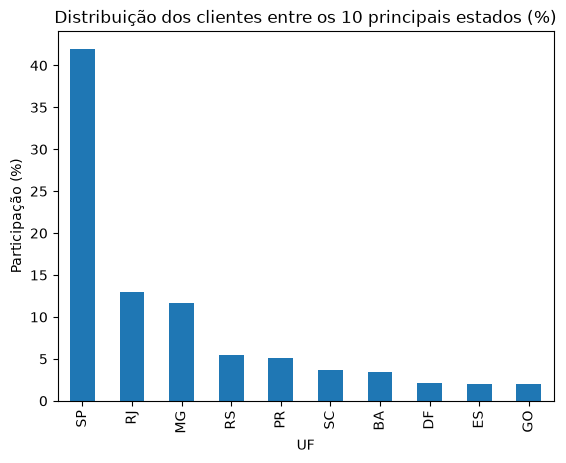

In [19]:
participacao_uf.head(10).plot(kind='bar', title='Distribuição dos clientes entre os 10 principais estados (%)', xlabel='UF', ylabel= 'Participação (%)');

**Observação:**
- Há clientes nos 27 estados.
- Os clientes estão concentrados no Sudeste. SP, RJ e MG somam 67% dos clientes.

### 4.3 Recompra

In [20]:
total_pedidos = clientes.shape[0]
pessoas_unicas = clientes['customer_unique_id'].nunique()
diferenca = total_pedidos - pessoas_unicas
percentual = diferenca/total_pedidos*100

print('Pedidos:', total_pedidos)
print('Pessoas únicas:', pessoas_unicas)
print('Diferença:', diferenca)
print('Compras de quem já era cliente:', round(percentual, 1), '%')


Pedidos: 99441
Pessoas únicas: 96096
Diferença: 3345
Compras de quem já era cliente: 3.4 %


**Observação:**
- São 99.441 pedidos feitos por 96.096 pessoas.
- Só 3,4% das compras vêm de quem já tinha comprado antes, recompra baixa.

### 4.4 Formas de pagamento

In [21]:
pagamentos ['payment_type'].value_counts(normalize=True) *100

payment_type
credit_card    73.922376
boleto         19.043952
voucher         5.558978
debit_card      1.471806
not_defined     0.002888
Name: proportion, dtype: float64

**Observação:**
- O cartão de crédito detém cerca de 74% dos pagamentos, e em seguida, o boleto com 19%

### 4.5 Preço dos produtos

In [22]:
itens['price'].describe()

count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64

**Observação:**

- O preço médio é de R\$ 120, mas a mediana é de R\$ 75
- Poucos produtos com preços elevados (até R\$6.735) elevam a média, gerando uma distribuição assimétrica à direita.
- Mediana representa melhor o preço típico dos produtos

### 4.6 Prazos de entrega

In [23]:
pedidos['order_purchase_timestamp'] = pd.to_datetime(pedidos['order_purchase_timestamp'])
pedidos['order_delivered_carrier_date'] = pd.to_datetime(pedidos['order_delivered_carrier_date'])
pedidos['order_delivered_customer_date'] = pd.to_datetime(pedidos['order_delivered_customer_date'])
pedidos['order_estimated_delivery_date'] = pd.to_datetime(pedidos['order_estimated_delivery_date'])

In [24]:
pedidos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  object        
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](4), object(4)
memory usage: 6.1+ MB


In [25]:
entregues = pedidos[pedidos['order_status'] == 'delivered']
entregues = entregues[entregues['order_delivered_customer_date'].notna()].copy()

entregues.shape

(96470, 8)

In [26]:
entregues['dias_entrega'] = (entregues['order_delivered_customer_date'] - entregues['order_purchase_timestamp']).dt.days
entregues['dias_entrega'].describe()

count    96470.000000
mean        12.093604
std          9.551380
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        209.000000
Name: dias_entrega, dtype: float64

In [27]:
entregues['atrasado'] = entregues['order_delivered_customer_date'] > entregues['order_estimated_delivery_date']
entregues['atrasado'].value_counts()

atrasado
False    88644
True      7826
Name: count, dtype: int64

In [28]:
percentual_atraso = entregues['atrasado'].mean()*100
print('Pedidos atrasados:', round(percentual_atraso, 1), '%')

Pedidos atrasados: 8.1 %


In [29]:
entregues['dias_folga'] = (entregues['order_estimated_delivery_date'] - entregues['order_delivered_customer_date']).dt.days
entregues['dias_folga'].describe()

count    96470.000000
mean        10.875889
std         10.182105
min       -189.000000
25%          6.000000
50%         11.000000
75%         16.000000
max        146.000000
Name: dias_folga, dtype: float64

**Observação:**
- Em média, um pedido leva cerca de 12 dias para ser entregue.
- Em média, um pedido tem cerca de 11 dias de folga da data estimada de entrega para a data de entrega.
- 8,1% dos pedidos chegaram depois da data prevista.

### 4.7 Observações gerais

- 14,7% das avaliações são ruins (nota 1 ou 2), e a nota 1 é mais comum que as notas 2 e 3.
- 8,1% dos pedidos entregues chegaram depois da data prevista (7.826 pedidos).
- Em média, os pedidos chegam cerca de 11 dias antes do prometido: os prazos informados são folgados.
- Só 3,4% das compras vêm de clientes que já tinham comprado antes.

As avaliações ruins e os atrasos aparecem em proporções parecidas,
o que sugere uma possível relação entre eles. Se confirmada, essa relação aponta
para ações concretas na logística, com impacto na satisfação e, potencialmente,
na recompra.

**Pergunta norteadora:** Como os atrasos na entrega afetam a satisfação do cliente,
e onde a Olist deve agir para reduzi-los?


## 05. Preparação dos dados

### 5.1 Avaliação por pedido

In [30]:
print('Linhas da tabela avaliacoes:', avaliacoes.shape[0])
print('Pedidos diferentes:', avaliacoes['order_id'].nunique())

Linhas da tabela avaliacoes: 99224
Pedidos diferentes: 98673


In [31]:
avaliacoes_unicas = avaliacoes.drop_duplicates(subset='order_id')
avaliacoes_unicas.shape

(98673, 7)

**Observação:** 551 pedidos tinham mais de uma avaliação. Mantido só uma por
pedido, para que nenhum pedido seja contado duas vezes.

### 5.2 Juntando as tabelas

In [32]:
base = entregues.merge(
    avaliacoes_unicas[['order_id', 'review_score']],
    on='order_id',
    how='left'
)

base = base.merge(
    clientes[['customer_id', 'customer_state']],
    on='customer_id',
    how='left'
)

base.shape

(96470, 13)

In [33]:
print('Pedidos sem avaliação:', base['review_score'].isna().sum())
print('Pedidos sem estado:   ', base['customer_state'].isna().sum())

base.head()

Pedidos sem avaliação: 646
Pedidos sem estado:    0


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,dias_entrega,atrasado,dias_folga,review_score,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8,False,7,4.0,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13,False,5,4.0,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9,False,17,5.0,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13,False,12,5.0,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2,False,9,5.0,SP


In [34]:
base.shape

(96470, 13)

**Observação:**

- Juntos em uma tabela única (`base`) o atraso, a nota e o estado de cada pedido entregue.
- A tabela tem 96.470 linhas, o mesmo número de pedidos entregues: nenhum pedido foi duplicado.
- 646 pedidos não têm avaliação (0,7%). Eles ficam de fora das análises de nota.

## 06. Análise

### 6.1 Atraso e satisfação

Pedidos entregues com atraso recebem notas piores do que pedidos entregues no prazo?

In [35]:
base.groupby('atrasado')['review_score'].mean()

atrasado
False    4.294500
True     2.565461
Name: review_score, dtype: float64

In [36]:
com_nota = base[base['review_score'].notna()].copy()
com_nota['nota_ruim'] = com_nota['review_score'] <= 2

com_nota.groupby('atrasado')['nota_ruim'].mean() * 100

atrasado
False     9.214750
True     54.066049
Name: nota_ruim, dtype: float64

In [37]:
percentual_ruim = com_nota.groupby('atrasado')['nota_ruim'].mean() * 100
percentual_ruim = percentual_ruim.rename({False: 'No prazo', True: 'Atrasado'})

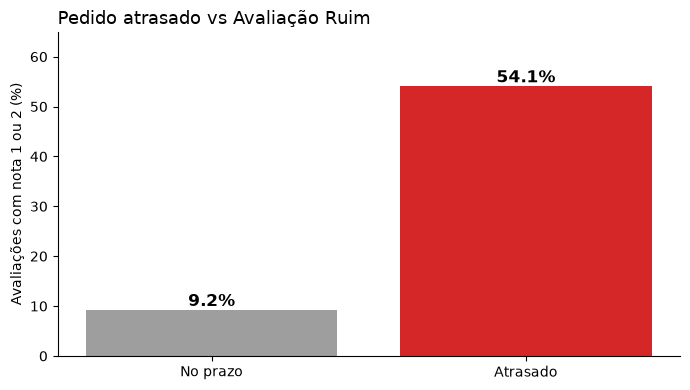

In [38]:
fig, ax = plt.subplots(figsize=(7, 4))

barras = ax.bar(percentual_ruim.index, percentual_ruim.values, color=['#9E9E9E', '#D62728'])
ax.bar_label(barras, fmt='%.1f%%', fontsize=12, fontweight='bold')

ax.set_title('Pedido atrasado vs Avaliação Ruim', fontsize=13, loc='left')
ax.set_ylabel('Avaliações com nota 1 ou 2 (%)')
ax.set_ylim(0, percentual_ruim.max() * 1.2)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

**Observações:**

- A nota média dos pedidos no prazo é 4,3; a dos atrasados é 2,6.
- Pedidos no prazo recebem 9,2% de avaliações ruins (nota 1 ou 2); os atrasados, 54,1%: quase 6 vezes mais.
- Mais da metade dos clientes que recebem com atraso dão nota 1 ou 2.

### 6.2 Efeito do tempo de atraso

A nota piora conforme aumentam os dias de atraso?

In [39]:
com_nota['dias_atraso'] = -com_nota['dias_folga']

In [40]:
com_nota['faixa_atraso'] = pd.cut(
    com_nota['dias_atraso'],
    bins=[-1000, 0, 3, 7, 14, 1000],
    labels=['No prazo', '1 a 3 dias', '4 a 7 dias', '8 a 14 dias', '15 dias ou mais']
)

com_nota['faixa_atraso'].value_counts()

faixa_atraso
No prazo           88163
1 a 3 dias          2636
4 a 7 dias          1773
8 a 14 dias         1748
15 dias ou mais     1504
Name: count, dtype: int64

In [41]:
ruim_por_faixa = com_nota.groupby('faixa_atraso', observed=True)['nota_ruim'].mean() * 100
ruim_por_faixa

faixa_atraso
No prazo            9.214750
1 a 3 dias         19.157815
4 a 7 dias         61.308517
8 a 14 dias        78.032037
15 dias ou mais    78.856383
Name: nota_ruim, dtype: float64

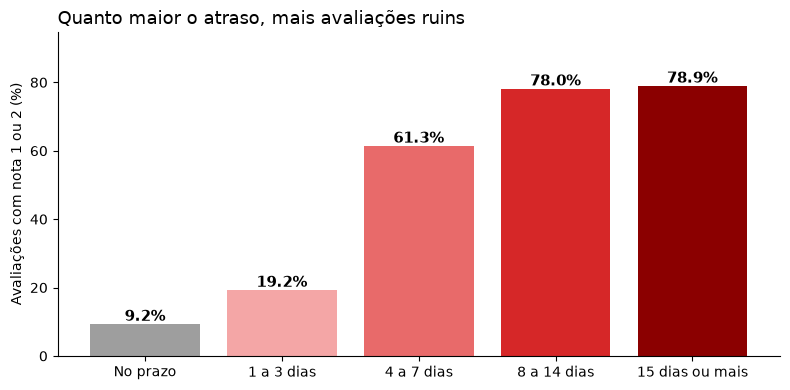

In [42]:
fig, ax = plt.subplots(figsize=(8, 4))

cores = ['#9E9E9E', '#F4A6A6', '#E86A6A', '#D62728', '#8B0000']
barras = ax.bar(ruim_por_faixa.index, ruim_por_faixa.values, color=cores)
ax.bar_label(barras, fmt='%.1f%%', fontsize=11, fontweight='bold')

ax.set_title('Quanto maior o atraso, mais avaliações ruins', fontsize=13, loc='left')
ax.set_ylabel('Avaliações com nota 1 ou 2 (%)')
ax.set_ylim(0, ruim_por_faixa.max() * 1.2)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

**Observações:**

- Quanto maior o atraso, maior o percentual de avaliações ruins.
- Atrasos de até 3 dias têm impacto moderado (19,2%), mas a partir de 4 dias o percentual salta para 61,3%.
- Acima de 8 dias, cerca de 78% das avaliações são ruins, e o percentual se estabiliza.
- O limite crítico é de cerca de 3 dias: evitar atrasos maiores que isso deve ser a prioridade.

### 6.3 Peso dos atrasos nas avaliações ruins

De todas as avaliações ruins, quantas vêm de pedidos atrasados?

In [43]:
avaliacoes_ruins = com_nota[com_nota['nota_ruim']]

print('Total de avaliações ruins:', avaliacoes_ruins.shape[0])
print('Vindas de pedidos atrasados:', avaliacoes_ruins['atrasado'].sum())
print('Percentual:', round(avaliacoes_ruins['atrasado'].mean() * 100, 1), '%')

Total de avaliações ruins: 12266
Vindas de pedidos atrasados: 4142
Percentual: 33.8 %


**Observações:**

- Os atrasos são 8,1% dos pedidos, mas geram 33,8% das avaliações ruins.

**Conclusão:** O atraso está fortemente associado à
insatisfação do cliente. Como se trata de uma associação, o atraso pode não ser
a única causa das notas ruins, mas a diferença entre os grupos é muito grande.

### 6.4 Atrasos por estado e região

Os atrasos se concentram em alguns estados e região?

In [44]:
por_uf = base.groupby('customer_state')['atrasado']

resumo_uf = pd.DataFrame({
    'pedidos': por_uf.size(),
    'atrasados': por_uf.sum(),
    'pct_atraso': por_uf.mean() * 100
})

resumo_uf = resumo_uf.sort_values('pct_atraso', ascending=False)
resumo_uf.round(1)

,pedidos,atrasados,pct_atraso
customer_state,,,
AL,397,95,23.9
MA,717,141,19.7
PI,476,76,16.0
CE,1279,196,15.3
SE,335,51,15.2
BA,3256,457,14.0
RJ,12350,1664,13.5
TO,274,35,12.8
PA,946,117,12.4


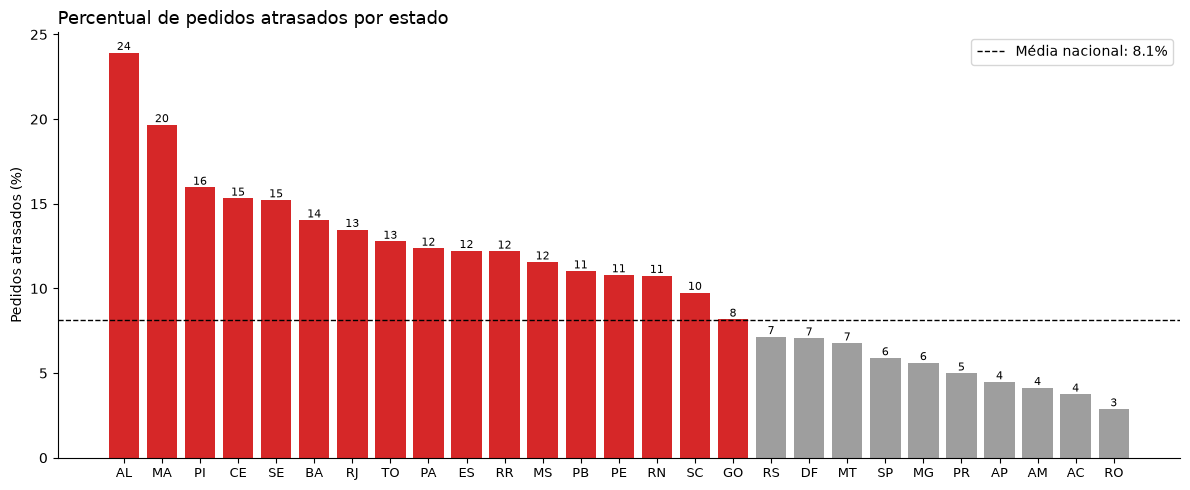

In [45]:
media = base['atrasado'].mean() * 100
cores = ['#D62728' if valor > media else '#9E9E9E' for valor in resumo_uf['pct_atraso']]

fig, ax = plt.subplots(figsize=(12, 5))

barras = ax.bar(resumo_uf.index, resumo_uf['pct_atraso'], color=cores)
ax.bar_label(barras, fmt='%.0f', fontsize=8)
ax.axhline(media, color='black', linestyle='--', linewidth=1, label=f'Média nacional: {media:.1f}%')

ax.set_title('Percentual de pedidos atrasados por estado', fontsize=13, loc='left')
ax.set_ylabel('Pedidos atrasados (%)')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(axis='x', labelsize=9)

plt.tight_layout()
plt.show()

In [46]:
resumo_uf['pct_do_total'] = resumo_uf['atrasados'] / resumo_uf['atrasados'].sum() * 100

resumo_uf.sort_values('atrasados', ascending=False).head(10).round(1)

,pedidos,atrasados,pct_atraso,pct_do_total
customer_state,,,,
SP,40494,2387,5.9,30.5
RJ,12350,1664,13.5,21.3
MG,11354,637,5.6,8.1
BA,3256,457,14.0,5.8
RS,5344,382,7.1,4.9
SC,3546,346,9.8,4.4
PR,4923,246,5.0,3.1
ES,1995,244,12.2,3.1
CE,1279,196,15.3,2.5


In [47]:
regioes = {
    'AC': 'Norte', 'AP': 'Norte', 'AM': 'Norte', 'PA': 'Norte', 'RO': 'Norte', 'RR': 'Norte', 'TO': 'Norte',
    'AL': 'Nordeste', 'BA': 'Nordeste', 'CE': 'Nordeste', 'MA': 'Nordeste', 'PB': 'Nordeste',
    'PE': 'Nordeste', 'PI': 'Nordeste', 'RN': 'Nordeste', 'SE': 'Nordeste',
    'DF': 'Centro-Oeste', 'GO': 'Centro-Oeste', 'MT': 'Centro-Oeste', 'MS': 'Centro-Oeste',
    'ES': 'Sudeste', 'MG': 'Sudeste', 'RJ': 'Sudeste', 'SP': 'Sudeste',
    'PR': 'Sul', 'RS': 'Sul', 'SC': 'Sul'
}

base['regiao'] = base['customer_state'].map(regioes)
base['regiao'].value_counts()

regiao
Sudeste         66193
Sul             13813
Nordeste         9044
Centro-Oeste     5624
Norte            1796
Name: count, dtype: int64

In [48]:
por_regiao = base.groupby('regiao')['atrasado']

resumo_regiao = pd.DataFrame({
    'pedidos': por_regiao.size(),
    'atrasados': por_regiao.sum(),
    'pct_atraso': por_regiao.mean() * 100
})
resumo_regiao['pct_do_total'] = resumo_regiao['atrasados'] / resumo_regiao['atrasados'].sum() * 100

resumo_regiao = resumo_regiao.sort_values('pct_atraso', ascending=False)
resumo_regiao.round(1)

,pedidos,atrasados,pct_atraso,pct_do_total
regiao,,,,
Nordeste,9044,1296,14.3,16.6
Norte,1796,176,9.8,2.2
Centro-Oeste,5624,448,8.0,5.7
Sudeste,66193,4932,7.5,63.0
Sul,13813,974,7.1,12.4


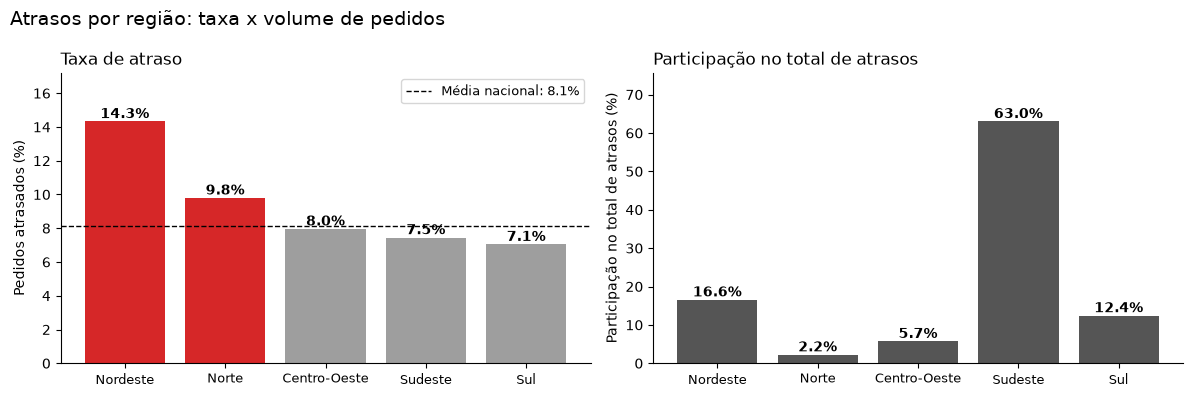

In [49]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

cores_regiao = ['#D62728' if valor > media else '#9E9E9E' for valor in resumo_regiao['pct_atraso']]
barras1 = ax1.bar(resumo_regiao.index, resumo_regiao['pct_atraso'], color=cores_regiao)
ax1.bar_label(barras1, fmt='%.1f%%', fontsize=10, fontweight='bold')
ax1.axhline(media, color='black', linestyle='--', linewidth=1, label=f'Média nacional: {media:.1f}%')
ax1.set_title('Taxa de atraso', fontsize=12, loc='left')
ax1.set_ylim(0, resumo_regiao['pct_atraso'].max() * 1.2)
ax1.set_ylabel('Pedidos atrasados (%)')
ax1.legend(fontsize=9)

barras2 = ax2.bar(resumo_regiao.index, resumo_regiao['pct_do_total'], color='#555555')
ax2.bar_label(barras2, fmt='%.1f%%', fontsize=10, fontweight='bold')
ax2.set_title('Participação no total de atrasos', fontsize=12, loc='left')
ax2.set_ylim(0, resumo_regiao['pct_do_total'].max() * 1.2)
ax2.set_ylabel('Participação no total de atrasos (%)')

for ax in (ax1, ax2):
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='x', labelsize=9)

fig.suptitle('Atrasos por região: taxa x volume de pedidos', fontsize=14, x=0.01, ha='left')
plt.tight_layout()
plt.show()

**Observações:**

- O Nordeste tem a maior taxa de atraso (14,3%), e o Norte, também fica acima da média (9,8%).
- O Sudeste tem taxa abaixo da média (7,5%), mas concentra 63% de todos os pedidos atrasados pelo volume de clientes.
- O Nordeste aparece nas duas frentes: tem a pior taxa e é a segunda região em volume de atrasos (16,6%).
- Exceção: o RJ, mesmo próximo dos vendedores, tem taxa de atraso de 13,5% e responde por 21,3% de todos os atrasos. A distância não explica esse caso, o que indica problemas logísticos locais

**Conclusão:** Os atrasos não se distribuem por igual.
- Sudeste: pequenas melhorias na taxa reduzem o maior número de atrasos.
- Nordeste: melhorias estruturais na logística, com potencial de reduzir a insatisfação e de apoiar o crescimento numa região onde a Olist ainda tem poucos clientes.

### 6.5 Onde o atraso acontece?

O atraso acontece na etapa do vendedor (até despachar o pedido) ou na etapa do transporte (até chegar ao cliente)?

In [50]:
base['dias_vendedor'] = (base['order_delivered_carrier_date'] - base['order_purchase_timestamp']).dt.days
base['dias_transporte'] = (base['order_delivered_customer_date'] - base['order_delivered_carrier_date']).dt.days

base[['dias_vendedor', 'dias_transporte']].describe()

,dias_vendedor,dias_transporte
count,96469.000000,96469.000000
mean,2.736402,8.878054
std,3.611423,8.745881
min,-172.000000,-17.000000
25%,1.000000,4.000000
50%,2.000000,7.000000
75%,4.000000,12.000000
max,125.000000,205.000000


In [51]:
print('Etapa do vendedor negativa:', (base['dias_vendedor'] < 0).sum())
print('Etapa do transporte negativa:', (base['dias_transporte'] < 0).sum())

Etapa do vendedor negativa: 165
Etapa do transporte negativa: 23


In [52]:
etapas = base.groupby('atrasado')[['dias_vendedor', 'dias_transporte']].mean()
etapas = etapas.rename(index={False: 'No prazo', True: 'Atrasado'})
etapas.round(1)

,dias_vendedor,dias_transporte
atrasado,,
No prazo,2.5,7.4
Atrasado,5.4,25.2


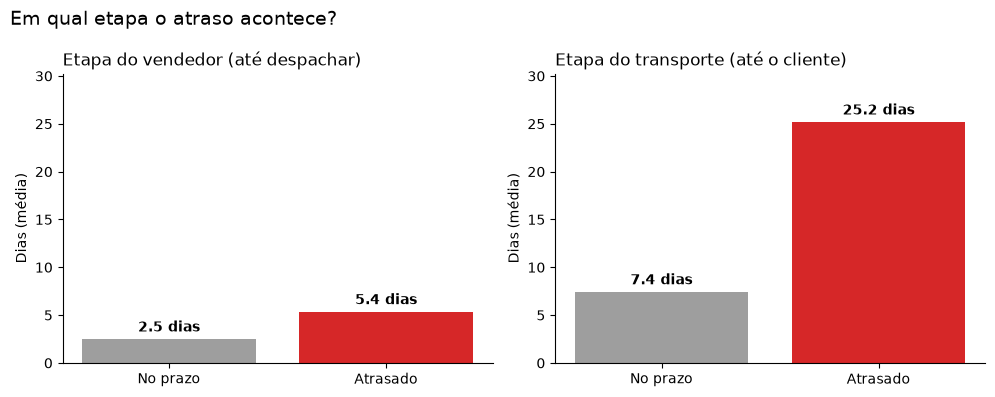

In [53]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

barras1 = ax1.bar(etapas.index, etapas['dias_vendedor'], color=['#9E9E9E', '#D62728'])
ax1.bar_label(barras1, fmt='%.1f dias', fontsize=10, fontweight='bold', padding=3)
ax1.set_title('Etapa do vendedor (até despachar)', fontsize=12, loc='left')
ax1.set_ylabel('Dias (média)')

barras2 = ax2.bar(etapas.index, etapas['dias_transporte'], color=['#9E9E9E', '#D62728'])
ax2.bar_label(barras2, fmt='%.1f dias', fontsize=10, fontweight='bold', padding=3)
ax2.set_title('Etapa do transporte (até o cliente)', fontsize=12, loc='left')
ax2.set_ylabel('Dias (média)')

for ax in (ax1, ax2):
    ax.set_ylim(0, etapas.max().max() * 1.2)
    ax.spines[['top', 'right']].set_visible(False)

fig.suptitle('Em qual etapa o atraso acontece?', fontsize=14, x=0.01, ha='left')
plt.tight_layout()
plt.show()

**Observação:**
- Nos pedidos no prazo, a etapa do vendedor leva 2,5 dias e a do transporte, 7,4 dias.
- Nos pedidos atrasados, a etapa do vendedor leva em média 5,4 dias e a do transporte, 25,2 dias.

**Conclusão:**
O principal gargalo está na etapa do transporte até o cliente, sendo o período que mais se alonga após o envio dos pedidos.

### 6.6 Por que o Norte e Nordeste tem mais incidência de atraso?

O tempo de transporte é maior para as regiões com mais atraso? Os vendedores estão concentrados longe delas?

In [54]:
etapas_regiao = base.groupby('regiao')[['dias_vendedor', 'dias_transporte']].mean()
etapas_regiao.sort_values('dias_transporte', ascending=False).round(1)

,dias_vendedor,dias_transporte
regiao,,
Norte,2.9,18.8
Nordeste,2.9,16.2
Centro-Oeste,2.7,11.4
Sul,2.7,10.3
Sudeste,2.7,7.1


In [55]:
vendedores['regiao'] = vendedores['seller_state'].map(regioes)
vendedores['regiao'].value_counts(normalize=True) * 100

regiao
Sudeste         73.893376
Sul             21.583199
Centro-Oeste     2.552504
Nordeste         1.809370
Norte            0.161551
Name: proportion, dtype: float64

**Observações:**

- A etapa do vendedor leva tempos parecidos em todas as regiões (entre 2,7 e 2,9 dias).
- Já a etapa do transporte é bem mais longa para o Nordeste (cerca de 16 dias) e o Norte (cerca de 19 dias) do que para o Sudeste (7 dias).
- 73,89% dos vendedores estão no Sudeste e 22% no Sul; Nordeste e Norte somam só 2%.

**Conclusão:** os dados indicam que a taxa de atraso mais alta no Norte e Nordeste está ligada à distância: a maior parte dos vendedores está no Sudeste, e o transporte até as regiões mais distantes é mais demorado.

### 6.7 Simulação de impacto

Se a Olist conseguisse evitar que os atrasos passassem de 3 dias, quantas avaliações ruins deixariam de existir?

In [56]:
atrasos_graves = com_nota[com_nota['dias_atraso']>= 4]
ruins_hoje = atrasos_graves['nota_ruim'].sum()

taxa_atraso_curto = ruim_por_faixa['1 a 3 dias'] / 100
ruins_simulado = atrasos_graves.shape[0] * taxa_atraso_curto

evitadas = ruins_hoje - ruins_simulado
total_ruins = com_nota['nota_ruim'].sum()

print('Pedidos com atraso de 4 dias ou mais:', atrasos_graves.shape[0])
print('Avaliações ruins hoje nesses pedidos:', ruins_hoje)
print('Avaliações ruins se o atraso fosse de até 3 dias:', round(ruins_simulado))
print('Avaliações ruins evitadas:', round(evitadas))
print('Redução no total de avaliações ruins:', round(evitadas/total_ruins*100, 1), '%')

Pedidos com atraso de 4 dias ou mais: 5025
Avaliações ruins hoje nesses pedidos: 3637
Avaliações ruins se o atraso fosse de até 3 dias: 963
Avaliações ruins evitadas: 2674
Redução no total de avaliações ruins: 21.8 %


**Observações:**

- Hoje, os 5.025 pedidos com 4 dias de atraso ou mais geram 3.637 avaliações ruins.
- Se esses atrasos fossem contidos em até 3 dias, seriam cerca de 963 avaliações ruins.
- Com a simulação, evitaria cerca de 2.674 avaliações negativas, uma redução de 21,8% no total.

É uma simulação simples, que supõe que esses clientes reagiriam como os que tiveram atraso curto. Ela indica a ordem de grandeza do ganho, não um valor exato.

### 6.8 Atraso, avaliação e recompra

Clientes que tiveram a primeira compra atrasada, ou que deram avaliação ruim, voltam a comprar menos?





In [57]:
base_recompra = base.merge(
    clientes[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

base_recompra.shape

(96470, 17)

In [58]:
base_recompra['data_compra'] = base_recompra['order_purchase_timestamp'].dt.date

compras_por_dia = base_recompra.drop_duplicates(subset=['customer_unique_id', 'data_compra'])
qtd_compras = compras_por_dia['customer_unique_id'].value_counts()

qtd_compras.head()

customer_unique_id
8d50f5eadf50201ccdcedfb9e2ac8455    15
ca77025e7201e3b30c44b472ff346268     7
1b6c7548a2a1f9037c1fd3ddfed95f33     7
6469f99c1f9dfae7733b25662e7f1782     6
63cfc61cee11cbe306bff5857d00bfe4     6
Name: count, dtype: int64

In [59]:
primeira_compra = base_recompra.sort_values('order_purchase_timestamp')
primeira_compra = primeira_compra.drop_duplicates(subset='customer_unique_id', keep='first').copy()

primeira_compra['voltou'] = primeira_compra['customer_unique_id'].map(qtd_compras) > 1

print('Pessoas:', primeira_compra.shape[0])
print('Voltaram a comprar:', primeira_compra['voltou'].sum())
print('Taxa de recompra: ', round(primeira_compra['voltou'].mean() * 100, 1), '%')

Pessoas: 93350
Voltaram a comprar: 2015
Taxa de recompra:  2.2 %


In [60]:
print('Recompra por situação da primeira entrega (%):')
print(primeira_compra.groupby('atrasado')['voltou'].mean() * 100)

com_nota_recompra = primeira_compra[primeira_compra['review_score'].notna()].copy()
com_nota_recompra['nota_ruim'] = com_nota_recompra['review_score'] <=2

print('\nRecompra por avaliação da primeira compra (%):')
print(com_nota_recompra.groupby('nota_ruim')['voltou'].mean() *100)

Recompra por situação da primeira entrega (%):
atrasado
False    2.205299
True     1.631150
Name: voltou, dtype: float64

Recompra por avaliação da primeira compra (%):
nota_ruim
False    2.223405
True     1.720954
Name: voltou, dtype: float64


**Observações:**

- Das 93.350 pessoas que receberam a primeira compra, só 2.015 voltaram a comprar (2,2%).
- Quem recebeu a primeira compra com atraso voltou menos: 1,6%, contra 2,2% de quem recebeu no prazo (cerca de 26% a menos).
- Quem deu avaliação ruim na primeira compra também voltou menos: 1,7%, contra 2,2% (cerca de 23% a menos).
- A diferença absoluta é pequena porque a recompra é baixa para todos: mesmo entre os clientes bem atendidos, só 2,2% voltam.

**Conclusão:** a experiência ruim na primeira compra está associada a uma recompra menor,
mas não explica sozinha a recompra tão baixa da Olist.

## 07. Conclusões e propostas de intervenção

### 7.1 Resposta à pergunta norteadora

**Como os atrasos na entrega afetam a satisfação do cliente?**

- Pedidos atrasados recebem 54,1% de avaliações ruins, contra 9,2% dos pedidos no prazo: quase 6 vezes mais.
- O efeito cresce com o tempo de atraso: até 3 dias, 19,2% de avaliações ruins; a partir de 4 dias, mais de 60%.
- Os atrasos são 8,1% dos pedidos, mas geram 33,8% de todas as avaliações ruins.
- O efeito chega à recompra: clientes com a primeira compra atrasada voltam cerca de 26% menos (1,6% contra 2,2%). Ainda assim, a recompra é baixa para todos os clientes.

**Onde a Olist deve agir?**

- **Na etapa do transporte:** nos pedidos atrasados, ela leva 17,8 dias a mais; a do vendedor, 2,9 dias a mais.
- **No Norte e no Nordeste:** maiores taxas de atraso (9,8% e 14,3%) e maiores tempos de transporte, longe dos vendedores (95% estão no Sudeste e no Sul).
- **No Rio de Janeiro:** mesmo perto dos vendedores, tem taxa de 13,5% e concentra 21,3% de todos os atrasos.
- **No Sudeste como um todo:** apesar da taxa abaixo da média, concentra 63% dos pedidos atrasados.

### 7.2 Propostas de intervenção

**1. Agir antes que o atraso passe de 3 dias**

Acompanhar os pedidos perto da data prevista, priorizar o envio e avisar o cliente, podendo
oferecer um cupom quando o atraso for inevitável.

*Motivo:* a partir de 4 dias de atraso, as avaliações ruins disparam. Contendo os atrasos
em até 3 dias, a simulação indica cerca de 21,8% menos avaliações ruins.


**2. Investigar os atrasos no Rio de Janeiro**

Analisar as transportadoras e rotas usadas no estado.

*Motivo:* mesmo perto dos vendedores, o RJ concentra 21,3% de todos os atrasos do país.


**3. Cobrar prazo de postagem dos vendedores**

Acompanhar quanto tempo cada vendedor leva para despachar o pedido.

*Motivo:* nos pedidos atrasados, o tempo do vendedor dobra (de 2,5 para 5,4 dias).


**4. Melhorar a entrega para o Norte e o Nordeste**

Buscar transportadoras regionais e avaliar um centro de distribuição na região.

*Motivo:* o transporte para essas regiões leva mais que o dobro do tempo, e quase não há vendedores lá.

As propostas estão em ordem de facilidade: as duas primeiras têm efeito mais rápido; a 4 é um investimento de médio prazo.

### 7.3 Ressalvas da análise

- Os dados mostram **associação**, não causa: o atraso está fortemente ligado às notas ruins, mas não é a única explicação. Dois terços das avaliações ruins vêm de pedidos entregues no prazo, o que indica outras causas (produto, atendimento, embalagem), não analisadas aqui.
- A **distância** entre vendedor e cliente não foi medida diretamente; ela é inferida a partir da região dos vendedores e dos tempos de transporte.
- A simulação de impacto é uma estimativa simples, que indica a ordem de grandeza do ganho.
